# Klasifikasi Genre Film (IMDb)

**Dataset:** `train_data.txt` (54.214 film), `test_data.txt` (54.200 film tanpa genre), dan `test_data_solution.txt` (kunci jawaban test). Format: `ID ::: JUDUL ::: GENRE ::: DESKRIPSI`.

**Catatan penting:** setelah diperiksa, **setiap film hanya memiliki tepat satu genre** (27 genre, tidak ada film dengan genre ganda). Jadi data ini sebenarnya **klasifikasi multikelas (single-label)**, bukan multilabel. Notebook ini tetap dikerjakan lengkap dan dilengkapi metrik **top-k** yang mendekati perilaku multilabel (rekomendasi beberapa genre teratas).

**Pertanyaan:**
1. Genre mana yang dominan dan mana yang langka?
2. Seberapa akurat genre ditebak dari judul dan sinopsis?
3. Jika model boleh menyebut 3 genre teratas, seberapa sering genre benar ikut disebut?

In [1]:
import glob, os
def cari(nama):
    # cari file di folder ini maupun subfolder
    h = glob.glob('**/'+nama, recursive=True)
    assert h, f"File {nama} tidak ditemukan di {os.getcwd()}"
    return h[0]
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import ComplementNB
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
sns.set_theme(style='whitegrid')
def baca(path, kolom):
    baris = [l.rstrip('\r\n').split(' ::: ') for l in open(path, encoding='utf-8')]
    return pd.DataFrame(baris, columns=kolom)
tr  = baca(cari('train_data.txt'), ['id','judul','genre','deskripsi'])
te  = baca(cari('test_data.txt'), ['id','judul','deskripsi'])
sol = baca(cari('test_data_solution.txt'), ['id','judul','genre','deskripsi'])
te = te.merge(sol[['id','genre']], on='id'); print(tr.shape, te.shape); tr.head(3)

(54214, 4) (54200, 4)


,id,judul,genre,deskripsi
0,1,Oscar et la dame rose (2009),drama,Listening in to a conversation between his doc...
1,2,Cupid (1997),thriller,A brother and sister with a past incestuous re...
2,3,"Young, Wild and Wonderful (1980)",adult,As the bus empties the students for their fiel...


## 1. Pemahaman Data

Genre unik: 27 | film dengan >1 genre: 0
Missing/kosong: 0


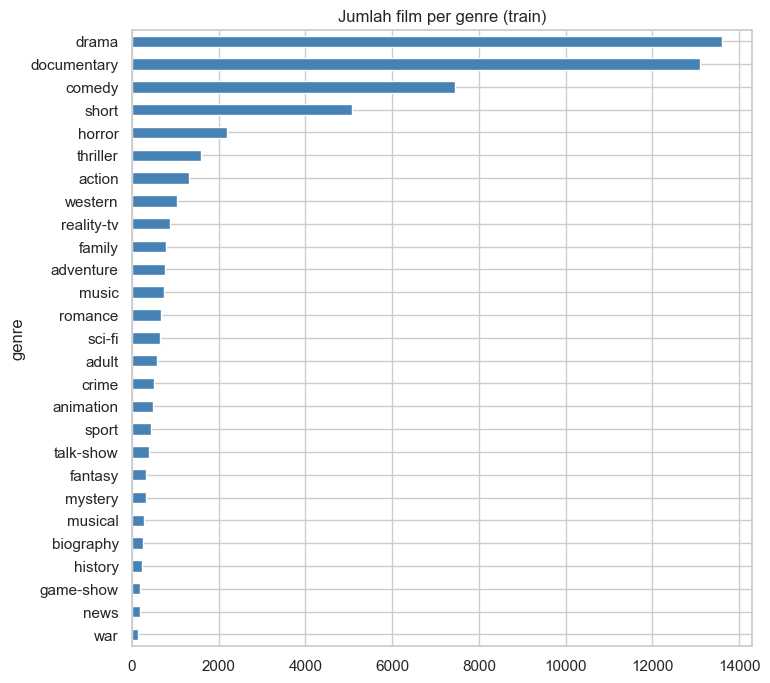

genre
drama          25.1 %
documentary    24.2 %
comedy         13.7 %
short           9.4 %
horror          4.1 %
Name: count, dtype: str
Rasio genre terbanyak/tersedikit: 103 x


In [2]:
print('Genre unik:', tr.genre.nunique(), '| film dengan >1 genre:', tr.genre.str.contains(r'[,|/;]').sum())
print('Missing/kosong:', (tr.deskripsi.str.strip()=='').sum())
cnt = tr.genre.value_counts()
cnt.sort_values().plot.barh(figsize=(8,8), color='steelblue', title='Jumlah film per genre (train)'); plt.show()
print((cnt/len(tr)*100).round(1).head(5).astype(str)+' %')
print('Rasio genre terbanyak/tersedikit:', cnt.max()//cnt.min(), 'x')

**Temuan:**
- **Drama (± 25%)** dan **Documentary (± 24%)** mendominasi; kedua genre ini saja hampir separuh data. Genre seperti *War* (132) dan *News* (181) sangat langka.
- Rasio genre terbanyak dibanding tersedikit sekitar **100 kali**, sehingga data sangat timpang.
- Model yang selalu menebak "drama" sudah mendapat akurasi ± 25%, jadi akurasi harus dibandingkan dengan angka itu. **F1-macro** dipakai agar genre kecil ikut diperhitungkan.

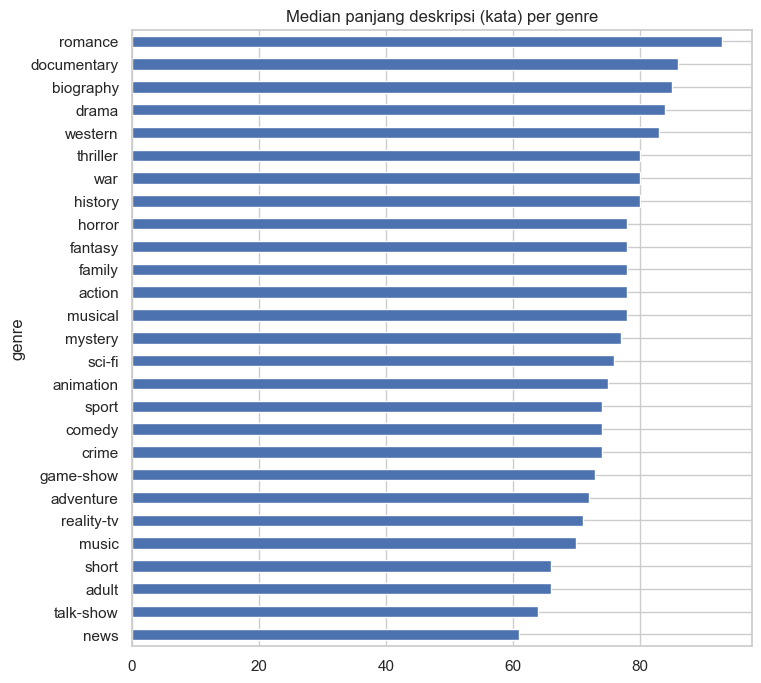

In [3]:
tr['panjang'] = tr.deskripsi.str.split().str.len()
tr.groupby('genre').panjang.median().sort_values().plot.barh(figsize=(8,8), title='Median panjang deskripsi (kata) per genre'); plt.show()

## 2. Pra-pemrosesan

In [4]:
tr['teks'] = tr.judul + ' ' + tr.deskripsi; te['teks'] = te.judul + ' ' + te.deskripsi
tfidf = TfidfVectorizer(stop_words='english', ngram_range=(1,2), min_df=3, max_features=300000, sublinear_tf=True)
A_tr = tfidf.fit_transform(tr.teks); A_te = tfidf.transform(te.teks)
print('Matriks TF-IDF:', A_tr.shape)

Matriks TF-IDF: (54214, 153838)


## 3. Pemodelan

In [5]:
models = {
 'Complement Naive Bayes': ComplementNB(alpha=0.3),
 'Linear SVM': LinearSVC(C=0.5),
 'Linear SVM (balanced)': LinearSVC(C=0.5, class_weight='balanced'),
}
hasil, skor = {}, {}
for n,m in models.items():
    m.fit(A_tr, tr.genre); p = m.predict(A_te)
    sc = m.decision_function(A_te) if hasattr(m,'decision_function') else m.predict_log_proba(A_te)
    top3 = np.argsort(-sc,axis=1)[:,:3]; kls = m.classes_
    t3 = np.mean([g in kls[r] for g,r in zip(te.genre, top3)])
    hasil[n] = dict(accuracy=accuracy_score(te.genre,p), F1_macro=f1_score(te.genre,p,average='macro'), F1_weighted=f1_score(te.genre,p,average='weighted'), Top3_accuracy=t3)
    skor[n] = p
base = (te.genre==tr.genre.value_counts().index[0]).mean()
print(f'Baseline (selalu menebak {tr.genre.value_counts().index[0]}): akurasi {base:.3f}')
pd.DataFrame(hasil).T.round(4)

Baseline (selalu menebak drama): akurasi 0.251


,accuracy,F1_macro,F1_weighted,Top3_accuracy
Complement Naive Bayes,0.5726,0.2841,0.5164,0.8233
Linear SVM,0.6158,0.3630,0.5821,0.8518
Linear SVM (balanced),0.5893,0.4082,0.5899,0.8182


**Cara membaca:**
- *Accuracy* dibandingkan dengan baseline di atas.
- *F1_macro* jauh lebih rendah daripada *F1_weighted* menandakan genre kecil banyak salah.
- **Top-3 accuracy** = proporsi film yang genre aslinya masuk 3 tebakan teratas. Ini lebih relevan untuk **sistem rekomendasi** atau penandaan otomatis, di mana menyebut beberapa kandidat genre sudah berguna.

**Temuan:** Linear SVM biasa memberi akurasi tertinggi (**± 61,6%**, top-3 ± 85,2%), sedangkan versi *balanced* mengorbankan sedikit akurasi (± 58,9%) demi **F1-macro lebih tinggi (± 0,41 vs ± 0,36)**, sehingga dipilih sebagai model terbaik menurut F1-macro. Semua model jauh di atas baseline (25,1%). F1-macro yang jauh di bawah F1-weighted (± 0,41 vs ± 0,59) menegaskan bahwa genre kecil banyak salah.

In [6]:
best = max(hasil, key=lambda k: hasil[k]['F1_macro']); p = skor[best]
print('Model terbaik (F1-macro):', best)
print(classification_report(te.genre, p, digits=3, zero_division=0))

Model terbaik (F1-macro): Linear SVM (balanced)
              precision    recall  f1-score   support

      action      0.382     0.529     0.444      1314
       adult      0.456     0.695     0.551       590
   adventure      0.332     0.333     0.333       775
   animation      0.282     0.277     0.279       498
   biography      0.051     0.027     0.035       264
      comedy      0.632     0.564     0.596      7446
       crime      0.203     0.242     0.221       505
 documentary      0.761     0.787     0.773     13096
       drama      0.693     0.581     0.632     13612
      family      0.255     0.290     0.271       783
     fantasy      0.188     0.205     0.196       322
   game-show      0.648     0.736     0.689       193
     history      0.124     0.070     0.089       243
      horror      0.547     0.757     0.635      2204
       music      0.476     0.731     0.576       731
     musical      0.212     0.221     0.216       276
     mystery      0.210     0.157

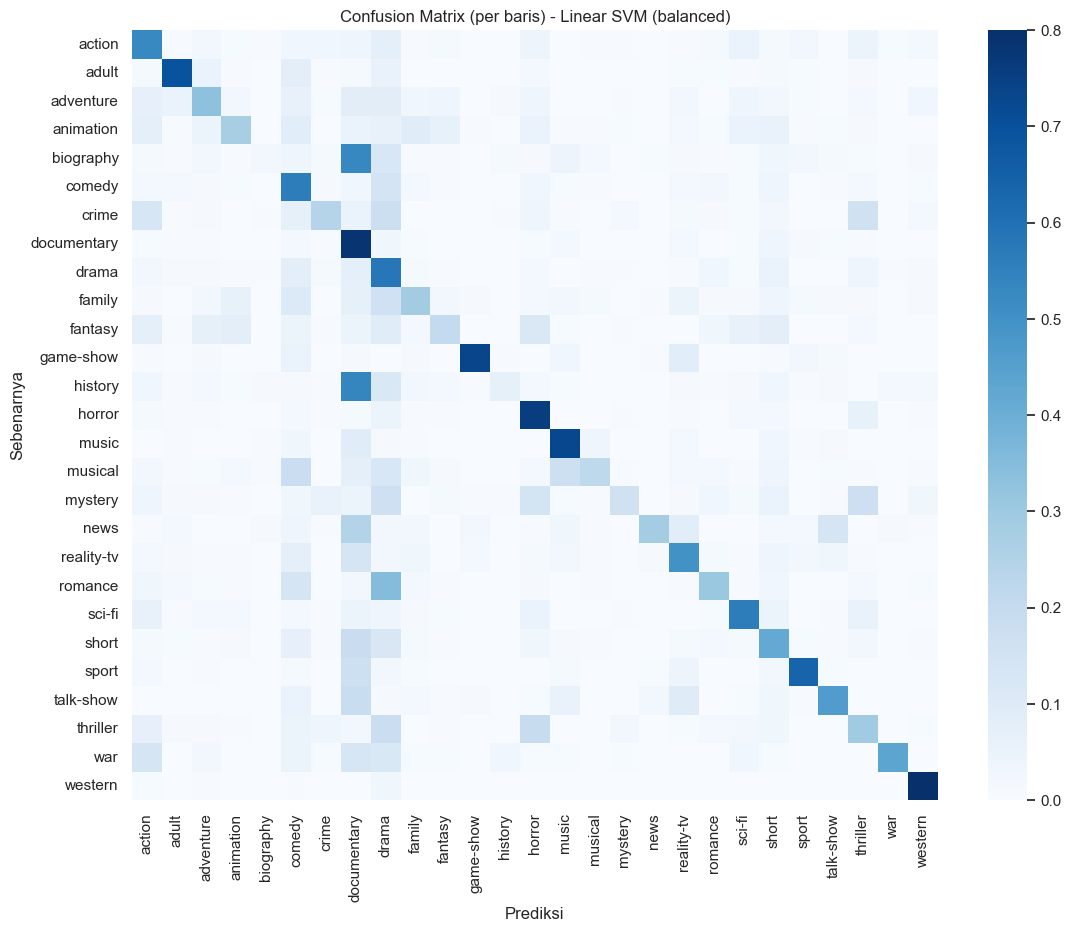

Pasangan genre yang paling sering tertukar:
  history diprediksi sebagai documentary: 54%
  biography diprediksi sebagai documentary: 53%
  romance diprediksi sebagai drama: 35%
  news diprediksi sebagai documentary: 25%
  thriller diprediksi sebagai horror: 19%
  talk-show diprediksi sebagai documentary: 19%


In [7]:
kls = sorted(tr.genre.unique())
cm = confusion_matrix(te.genre, p, labels=kls, normalize='true')
plt.figure(figsize=(13,10)); sns.heatmap(cm, xticklabels=kls, yticklabels=kls, cmap='Blues', vmax=0.8)
plt.xlabel('Prediksi'); plt.ylabel('Sebenarnya'); plt.title(f'Confusion Matrix (per baris) - {best}'); plt.show()
np.fill_diagonal(cm,0)
print('Pasangan genre yang paling sering tertukar:')
for a,b in np.dstack(np.unravel_index(np.argsort(-cm.ravel())[:6], cm.shape))[0]:
    print(f'  {kls[a]} diprediksi sebagai {kls[b]}: {cm[a,b]:.0%}')

**Cara membaca:** tiap baris adalah genre sebenarnya. Angka besar di luar diagonal menunjukkan genre yang sering dikira genre lain. Hasilnya: **History (54%) dan Biography (53%) lebih dari separuhnya diprediksi sebagai Documentary**, *Romance* sering dikira *Drama* (35%), dan *Thriller* dikira *Horror* (19%). Pasangan ini memang punya sinopsis yang mirip, dan genre yang tertukar biasanya genre kecil yang "tertelan" oleh genre besar.

In [8]:
m = models[best]
vocab = np.array(tfidf.get_feature_names_out())
if hasattr(m,'coef_'):
    for g in ['horror','documentary','animation','sci-fi','western']:
        i = list(m.classes_).index(g); print(f'{g:12s}:', ', '.join(vocab[np.argsort(-m.coef_[i])[:8]]))

horror      : horror, vampire, evil, blood, possessed, terror, satan, zombies
documentary : documentary, interviews, portrait, years, history, documents, intimate, israel
animation   : animated, animation, adventures, bheem, bratz, cartoon, duck, monster high
sci-fi      : alien, earth, scientist, future, space, time travel, government, futuristic
western     : ranch, sheriff, outlaw, outlaws, marshal, indians, west, cowboy


## 4. Kesimpulan
- Data ini **single-label dengan 27 genre**, sehingga lebih tepat dikelompokkan sebagai **klasifikasi multikelas**, bukan multilabel.
- Data sangat timpang (Drama dan Documentary ± 49% dari total), sehingga *accuracy* harus dibaca dibanding baseline dan dilengkapi **F1-macro**.
- Model linear berbasis TF-IDF sudah cukup kuat sebagai baseline. Kata-kata penciri genre bersifat masuk akal: *vampire, blood, zombies* untuk horror; *ranch, sheriff, outlaw, cowboy* untuk western; *animated, cartoon* untuk animation.
- Genre yang paling mudah: **Western (F1 ± 0,82)**, **Documentary (± 0,77)**, dan **Game-show (± 0,69)**, yang punya kosakata khas. Yang paling sulit: **Biography (± 0,04)** dan **History (± 0,09)**, nyaris tidak terdeteksi karena sinopsisnya mirip Documentary dan Drama.
- **Top-3 accuracy (± 82-85%)** jauh lebih tinggi dari akurasi biasa (± 57-62%), menunjukkan bahwa genre benar biasanya ada di antara kandidat teratas. Film sering memang memiliki beberapa genre, tetapi data hanya mencatat satu, sehingga sebagian "kesalahan" model sebenarnya masuk akal.
- **Langkah lanjutan:** jika ingin menjadikannya multilabel, perlu data dengan banyak genre per film (misalnya data IMDb lengkap) dan pendekatan One-vs-Rest atau model bahasa.